# Python Interview Flashcards (Session: Introduction to Python)

This notebook contains interview Q&A flashcards covering Python fundamentals, core architectural differences, tool comparisons (Excel/SQL), and the data science workflow, accompanied by runnable code examples.

*Note: These examples are just quick conceptual sketches to build intuition. Don't worry about the fine details yet—we'll break them down step by step in later notebooks!*

---
### 1: What is Python, and what are its primary paradigms and execution model?

**Answer:**
* **Definition**: Python is an easy-to-learn, powerful, very high-level programming language.
* **Paradigms**: It supports Object-Oriented, structured, and functional programming.
* **Execution Model**: It is an interpreted language; code is executed line-by-line rather than pre-compiled into machine code. This facilitates quick debugging, rapid experimentation, and platform independence across operating systems.

In [1]:
# Procedural/Structured
def add(a, b):
    return a + b

# Object-Oriented
class Adder:
    def __init__(self, val):
        self.val = val
    def add(self, x):
        return self.val + x

# Functional
numbers = [1, 2, 3]
doubled = list(map(lambda x: x * 2, numbers))
print(doubled)

[2, 4, 6]


In [2]:
# Demonstration: Line-by-line interpretation
print("Line 1 executes immediately.")
print("Line 2 executes next.")

# An error stops execution at the exact line it occurs without needing full compilation
try:
    print(10 / 0)
except ZeroDivisionError as e:
    print(f"Caught runtime exception: {e}")

Line 1 executes immediately.
Line 2 executes next.
Caught runtime exception: division by zero


---
### 2: How does Dynamic Typing work in Python compared to Statically Typed languages (C++/Java)?

**Answer:**
* In statically typed languages like Java or C++, variables require explicit type declarations at compile time.
* In Python, variables do not require type declarations; the interpreter determines the data type dynamically at runtime.
* A single variable name can reference different data types over its lifecycle.

In [3]:
# Demonstrating Dynamic Typing
data_container = 42
print(f"Value: {data_container}, Type: {type(data_container)}")

# Reassigning to a string
data_container = "Python is dynamically typed"
print(f"Value: {data_container}, Type: {type(data_container)}")

# Reassigning to a list
data_container = [1, 2, 3]
print(f"Value: {data_container}, Type: {type(data_container)}")

Value: 42, Type: <class 'int'>
Value: Python is dynamically typed, Type: <class 'str'>
Value: [1, 2, 3], Type: <class 'list'>


---
### 3: How does Memory Management differ between Python and C/C++?

**Answer:**
* **C / C++**: Requires manual memory allocation and deallocation (e.g., `malloc`/`free`, `new`/`delete`). Offers granular control and higher performance, but introduces risk of memory .
* **Python**: Manages memory automatically. When data structures (such as lists) are created, Python dynamically handles allocation and cleans up unused references. The trade-off is slightly slower execution speed.

In [4]:
import sys

# Dynamic list allocation without manual sizing
dynamic_list = []
for i in range(9):
    dynamic_list.append(i)

print(f"List contents: {dynamic_list}")
print(f"Memory size of list object: {sys.getsizeof(dynamic_list)} bytes")
# Python's garbage collector frees memory once references drop to zero
del dynamic_list


List contents: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Memory size of list object: 184 bytes


---
### 4: When would you use Python over Excel or SQL?

**Answer:**
* **Python vs Excel**: Excel works well for quick tabular entry and basic calculations, but is constrained by row limits and manual repetition. Python handles massive datasets beyond spreadsheet row limits, automates end-to-end extraction/reporting, and supports advanced statistical methods.
* **Python vs SQL**: SQL is purpose-built for querying and managing relational databases. Python complements SQL by providing advanced programmatic manipulation, automating database pipelines, running machine learning models, and interacting with file systems/APIs.

In [5]:
# Demonstrating an automated aggregation workflow beyond standard spreadsheet limits
raw_records = [
    {"region": "North", "sales": 250},
    {"region": "South", "sales": 400},
    {"region": "North", "sales": 150},
    {"region": "East", "sales": 300}
]

region_totals = {}
for record in raw_records:
    region = record["region"]
    region_totals[region] = region_totals.get(region, 0) + record["sales"]

print("Aggregated Sales Summary:", region_totals)

Aggregated Sales Summary: {'North': 400, 'South': 400, 'East': 300}


### 5. Why is Python described as platform-independent / cross-platform?

**Answer:** Python code can run on various operating systems (Windows, macOS, Linux) without modification as long as the target platform has a compatible Python interpreter installed.

In [6]:
import platform

print(f"Running on OS: {platform.system()}")
print(f"OS Release: {platform.release()}")

Running on OS: Linux
OS Release: 6.6.122+


### 6. What does "Free and Open Source" mean in Python's ecosystem?

**Answer:** Python is freely accessible to everyone at www.python.org without licensing fees, backed by a global developer community that continuously writes and maintains new packages and modules.


In [7]:
# You can freely install, import, and inspect open-source packages
import math
print(math.pi)

3.141592653589793


### 7. How does Python integrate with other programming languages?

**Answer:** Python is an integrated language that interfaces smoothly with languages like C, C++, and Java, allowing compute-heavy tasks to run in compiled code while using Python as an interface.


In [8]:
import ctypes

# Calling a standard C library function from Python
libc = ctypes.CDLL(None) if hasattr(ctypes.CDLL(None), 'puts') else None
# Python integrates directly with native system libraries
print("Integrated execution interface ready")

Integrated execution interface ready


### 8. How does Python handle runtime errors and exceptions?

**Answer:** Python provides built-in exception handling constructs (`try`, `except`, `finally`) to catch runtime issues cleanly without abruptly crashing the application.

In [9]:
def safe_convert(val):
  try:
    return int(val)
  except ValueError as e:
    print(f"Caught runtime exception: {e}")
    return None #Instead of abruptly crashing the application returns None
  finally:
    print("Execution complete")

print(safe_convert("123"))
print(safe_convert("abc"))

Execution complete
123
Caught runtime exception: invalid literal for int() with base 10: 'abc'
Execution complete
None


### 9. How is Python used in web development?

**Answer:** Python powers dynamic web applications using web frameworks such as Django and Flask, which simplify routing, request handling, and business logic.


In [10]:
# Conceptual Flask web route example
# from flask import Flask
# app = Flask(__name__)

def home_route():
    return {"status": 200, "message": "Welcome to Python Web Service"}

print(home_route())

{'status': 200, 'message': 'Welcome to Python Web Service'}


### 10. How does Python establish database connectivity?

**Answer:** Python connects to relational databases (e.g., SQLite, MySQL, PostgreSQL) and NoSQL databases (e.g., MongoDB) using standard drivers and connectors.


In [11]:
import sqlite3

# Connecting to an in-memory SQLite database
conn = sqlite3.connect(":memory:")
cursor = conn.cursor()
cursor.execute("CREATE TABLE users (id INT, name TEXT)")
cursor.execute("INSERT INTO users VALUES (1, 'Alice')")
conn.commit()

cursor.execute("SELECT * FROM users")
print(cursor.fetchall())

[(1, 'Alice')]


### 11. How is Python applied in automation and scripting?

**Answer:** Python scripts automate repetitive administrative tasks, file manipulation, batch processing, and system jobs using its extensive standard library.


In [12]:
import os

# Create a temporary directory, list contents, and clean up
os.makedirs("test_automation", exist_ok=True)
print("Directory created:", os.path.exists("test_automation"))
os.rmdir("test_automation")
print("Directory created:", os.path.exists("test_automation"))


Directory created: True
Directory created: False


### 12. What options exist for desktop GUI applications in Python?

**Answer:** Python provides libraries and toolkits (such as `tkinter`, PyQt, or wxPython) to build graphical user interfaces for desktop environments.


In [13]:
# Prerequisites
# 1. Update package indices and suppress repo warnings
!apt-get update -qq 2>/dev/null

# 2. Install headless X11 display server, screen capture utility, and Tkinter
!apt-get install -y -qq xvfb imagemagick python3-tk > /dev/null

# 3. Install Python imaging and HTTP client libraries
!pip install -q pyvirtualdisplay pillow requests

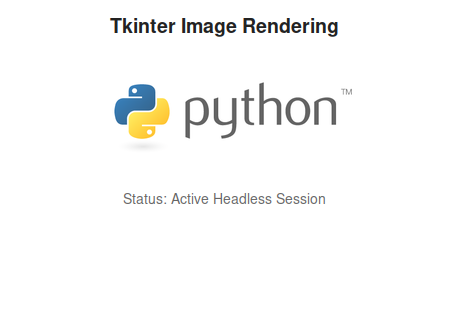

In [14]:
import io
import os
import requests
from PIL import Image, ImageTk
from IPython.display import Image as IPImage
from pyvirtualdisplay import Display

# 1. Match virtual screen size directly to app window dimensions
WIN_WIDTH, WIN_HEIGHT = 450, 320
disp = Display(visible=0, size=(WIN_WIDTH, WIN_HEIGHT))
disp.start()

try:
    import tkinter as tk

    # 2. High-res Python logo
    IMAGE_URL = "https://www.python.org/static/community_logos/python-logo-master-v3-TM.png"
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(IMAGE_URL, headers=headers, timeout=10)
    pil_img = Image.open(io.BytesIO(response.content))

    # Resize cleanly to fit inside the window
    pil_img = pil_img.resize((300, 100), Image.Resampling.LANCZOS)

    # 3. Build GUI
    root = tk.Tk()
    root.title("Desktop UI Preview")
    root.geometry(f"{WIN_WIDTH}x{WIN_HEIGHT}")
    root.configure(bg="#ffffff")

    title = tk.Label(
        root,
        text="Tkinter Image Rendering",
        font=("Helvetica", 14, "bold"),
        bg="#ffffff",
        fg="#222222"
    )
    title.pack(pady=16)

    # Convert to Tkinter PhotoImage and retain reference
    tk_img = ImageTk.PhotoImage(pil_img)
    lbl_img = tk.Label(root, image=tk_img, bg="#ffffff")
    lbl_img.image = tk_img
    lbl_img.pack(pady=10)

    status = tk.Label(
        root,
        text="Status: Active Headless Session",
        font=("Helvetica", 10),
        bg="#ffffff",
        fg="#666666"
    )
    status.pack(pady=12)

    root.update_idletasks()
    root.update()

    # 4. Crop snapshot strictly to window geometry (removes black margins)
    os.system(f"import -window root -crop {WIN_WIDTH}x{WIN_HEIGHT}+0+0 /tmp/clean_preview.png")
    root.destroy()

finally:
    disp.stop()

# 5. Render clean image inline
IPImage(filename="/tmp/clean_preview.png")

### 13. When should you use Python instead of Microsoft Excel?

**Answer:** Excel is limited by sheet row limits and requires manual interaction. Python processes datasets far exceeding spreadsheet capacity, handles complex multi-source data wrangling, and fully automates periodic analytical pipelines.


In [15]:
import random

# Simulating 1.2M transactions (exceeds Excel's 1,048,576 row hard limit)
CATEGORIES = ["Electronics", "Fashion", "Home & Kitchen", "Books", "Automotive"]

orders = (
    {
        "order_id": f"ORD-{i:07d}",
        "category": random.choice(CATEGORIES),
        "amount": round(random.uniform(5.0, 450.0), 2),
    }
    for i in range(1_200_000)  # Generator expression avoids allocating all dicts at once
)

# Header
print(f"{'Order ID':<15} | {'Category':<16} | {'Amount ($)':>10}")
print("-" * 47)

# Iterate only the first 5 records
for i, order in enumerate(orders):
    if i == 5:
        break
    print(f"{order['order_id']:<15} | {order['category']:<16} | {order['amount']:>10.2f}")
print("-" * 47)

# Single-pass aggregation: O(1) memory footprint
total_revenue = 0.0
category_counts = {}
record_count = 0

for order in orders:
    amount = order["amount"]
    category = order["category"]

    total_revenue += amount
    category_counts[category] = category_counts.get(category, 0) + 1
    record_count += 1

avg_ticket_size = total_revenue / record_count if record_count else 0.0

print(f"Total Transactions Processed : {record_count:,}")
print(f"Gross Revenue                : ${total_revenue:,.2f}")
print(f"Average Order Value (AOV)    : ${avg_ticket_size:.2f}")
print(f"Top Category By Volume       : {max(category_counts, key=category_counts.get)}")

Order ID        | Category         | Amount ($)
-----------------------------------------------
ORD-0000000     | Home & Kitchen   |      88.34
ORD-0000001     | Home & Kitchen   |     347.27
ORD-0000002     | Electronics      |      68.91
ORD-0000003     | Books            |     109.55
ORD-0000004     | Electronics      |      21.35
-----------------------------------------------
Total Transactions Processed : 1,199,994
Gross Revenue                : $273,039,057.89
Average Order Value (AOV)    : $227.53
Top Category By Volume       : Home & Kitchen


### 14. How does Python complement SQL in data tasks?

**Answer:** SQL excels at relational querying inside a database engine, whereas Python handles external programmatic automation, data extraction across diverse APIs, machine learning modeling, and operating system tasks outside the database.


In [16]:
# Python can ingest a SQL result, apply custom transforms, and pass to downstream tasks
mock_sql_result = [("ItemA", 100), ("ItemB", 250)]
transformed = {item: price * 1.05 for item, price in mock_sql_result}
print("Price after tax:", transformed)

Price after tax: {'ItemA': 105.0, 'ItemB': 262.5}


### 15. What role does Anaconda and Jupyter Notebook play in Python development?

**Answer:** Anaconda provides a packaged environment bundled with core scientific packages, while Jupyter Notebook allows interactive cell-by-cell execution, inline plotting, and rapid prototyping.


In [17]:
# Jupyter allows running independent blocks and displaying output immediately
notebook_cell_output = [x**2 for x in range(5)]
print("Cell Output:", notebook_cell_output)

Cell Output: [0, 1, 4, 9, 16]


---
### What are the 6 stages of the Data Science Pipeline in Python, and which libraries correspond to each?

**Answer:**
1. **Data Ingestion**: Fetching data from APIs, web scraping, or SQL databases.
2. **Data Wrangling**: Cleaning, reshaping, merging, and filtering via **pandas** and **NumPy**.
3. **Exploratory Data Analysis (EDA)**: Visualizing distributions, trends, and correlations via **matplotlib** and **seaborn** inside **Jupyter Notebooks**.
4. **Feature Engineering**: Creating transformed variables and derived features tailored to the problem.
5. **Model Training**: Fitting algorithms (Decision Trees, Random Forests, XGBoost via **scikit-learn**; CNNs, RNNs, Transformers via **TensorFlow** / **PyTorch**).
6. **Evaluation & Interpretation**: Cross-validation, metric analysis, and feature-importance evaluation.

---

**CNN (Convolutional Neural Network):**
* **Spatial Data** — grid-like structures such as images, computer vision tasks, and video frames.
***Example:** Image classification, facial recognition, medical imaging, and object detection.*


**RNN (Recurrent Neural Network):**
* **Sequential & Temporal Data** — ordered sequences where past context influences future elements.
 ***Example:** Time-series forecasting (e.g., stock prices, weather), speech-to-text, natural language processing (NLP), and translation.*



### 16. What happens during the Data Ingestion stage of a data science pipeline?

**Answer:** Data ingestion involves pulling raw information from diverse sources, including REST APIs, web scrapers, flat files, or SQL databases.

In [18]:
import json

# Simulating data ingestion from a JSON payload/API response
raw_api_payload = '{"status": "ok", "readings": [12.4, 14.1, 13.8]}'
parsed_data = json.loads(raw_api_payload)
print("Ingested readings:", parsed_data["readings"])

Ingested readings: [12.4, 14.1, 13.8]


### 17. What happens during the Data Wrangling stage, and which libraries are used?

**Answer:** Data wrangling cleans, merges, reshapes, and filters unstructured or messy records using core libraries like **pandas** and **NumPy**.

In [19]:
# Cleaning raw records (handling None values and casting types)
raw_table = [{"age": "25"}, {"age": None}, {"age": "30"}]
cleaned_ages = [int(r["age"]) for r in raw_table if r["age"] is not None]
print("Cleaned ages:", cleaned_ages)

Cleaned ages: [25, 30]


### 18. What is Exploratory Data Analysis (EDA), and what tools are used?

**Answer:** EDA involves summarizing data distributions, testing assumptions, finding outliers, and visualizing correlations using **matplotlib**, **seaborn**, and **Jupyter notebooks**.


In [20]:
values = [12, 15, 12, 18, 22, 19, 14, 100] # 100 is an outlier
mean_val = sum(values) / len(values)
print(f"Count: {len(values)}, Mean: {mean_val:.2f}")

Count: 8, Mean: 26.50


### 19. What is Feature Engineering in the context of Python data pipelines?

**Answer:** Feature engineering involves creating new, meaningful columns or input representations from raw variables to better expose the underlying pattern to machine learning models.


In [21]:
# Feature Engineering: Creating a weekend binary indicator from days
days = ["Monday", "Saturday", "Sunday"]
features = [{"day": d, "is_weekend": 1 if d in ["Saturday", "Sunday"] else 0} for d in days]
print(features)

[{'day': 'Monday', 'is_weekend': 0}, {'day': 'Saturday', 'is_weekend': 1}, {'day': 'Sunday', 'is_weekend': 1}]


In [22]:
# Simulated minimal pipeline: Feature Engineering & In-memory Processing
data_points = [
    {"sqft": 1200, "price": 250000},
    {"sqft": 1800, "price": 380000},
    {"sqft": 950, "price": 190000}
]

# Feature Engineering: Derive price-per-square-foot
for item in data_points:
    item["price_per_sqft"] = round(item["price"] / item["sqft"], 2)

print("Engineered Data:", data_points)

Engineered Data: [{'sqft': 1200, 'price': 250000, 'price_per_sqft': 208.33}, {'sqft': 1800, 'price': 380000, 'price_per_sqft': 211.11}, {'sqft': 950, 'price': 190000, 'price_per_sqft': 200.0}]


### 20. What is scikit-learn, and which classical ML algorithms does it provide?

**Answer:** Short for SciPy Toolkit for Machine Learning, `scikit-learn` is Python's standard library for classical models like Decision Trees, Random Forests, Support Vector Machines, and XGBoost wrappers.

```python
# Conceptual training pattern using standard scikit-learn estimator interface
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier()
clf.fit(X_train, y_train)
preds = clf.predict(X_test)
print("Standard model API: estimator.fit(X, y) -> estimator.predict(X)")
```

### Full Form

**scikit-learn** stands for **SciPy Toolkit for Machine Learning**.

* **Sci**: Short for **Scientific** (referencing **SciPy**, the foundational scientific Python library ecosystem).
* **Kit**: Short for **Toolkit** (third-party extensions built on top of SciPy are traditionally called "SciKits").
* **Learn**: Signifies its domain, **Machine Learning**.



---

### Meaning

In Python, a **SciKit** (Scientific Kit) is an independently maintained package that extends the core scientific computing capabilities of **SciPy** and **NumPy** for specific problem spaces (e.g., image processing with `scikit-image`, or machine learning with `scikit-learn`).

`scikit-learn` is Python's standard, production-ready library dedicated to **classical machine learning**. It provides standardized tools, interfaces, and algorithms for:

* **Classification**: Predicting categorical labels (e.g., Logistic Regression, Support Vector Machines, Random Forests).


* **Regression**: Predicting continuous values (e.g., Linear Regression, Ridge, Decision Trees).


* **Clustering**: Grouping unlabeled data points (e.g., K-Means, DBSCAN).
* **Dimensionality Reduction**: Compressing feature sets while preserving information (e.g., Principal Component Analysis / PCA).
* **Model Evaluation & Preprocessing**: Splitting datasets, cross-validation, hyperparameter tuning, and metric calculation.

### 21. What are Convolutional Neural Networks (CNNs), and what are their primary use cases?

**Answer:**

* **Primary Use Case:** Spatial Data — grid-like structures such as images, computer vision tasks, and video frames.

* **How It Works:** Instead of processing every pixel independently, CNNs slide mathematical filters (called kernels or convolutions) across the data to capture spatial hierarchies and local patterns (such as edges, textures, shapes, and complex objects).

* **Common Applications:** Image classification, facial recognition, medical imaging, and object detection.


In [23]:
# Conceptual 2D Convolution filter over a 3x3 pixel grid
image_patch = [
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1]
]
kernel = [
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1]
]
conv_result = sum(image_patch[i][j] * kernel[i][j] for i in range(3) for j in range(3))
print("Convolution dot product output:", conv_result)

Convolution dot product output: 5


### 22. What are Recurrent Neural Networks (RNNs), and what are their primary use cases?

**Answer:**
* **Primary Use Case:** Sequential & Temporal Data — ordered sequences where past context influences future elements.

* **How It Works:** Standard neural networks assume all inputs are independent. RNNs incorporate a recurrent internal loop ("hidden state") that acts as a short-term memory, carrying information from earlier steps in a sequence forward into subsequent steps.

* **Common Applications:** Time-series forecasting (e.g., stock prices, weather), speech-to-text, natural language processing (NLP), and translation.
###

In [24]:
# Simulating a simple recurrent hidden state step: h_t = activation(W * x_t + U * h_(t-1))
hidden_state = 0.0
sequence_inputs = [1.2, 0.8, -0.5]

for step_input in sequence_inputs:
    hidden_state = round(0.5 * hidden_state + 0.5 * step_input, 4)
    print(f"Updated hidden state: {hidden_state}")


Updated hidden state: 0.6
Updated hidden state: 0.7
Updated hidden state: 0.1


### Quick Comparison

| **Feature** | **CNN** | **RNN** |
| --- | --- | --- |
| **Data Specialty** | Spatial / Grid data (Images) | Sequential / Temporal data (Time series, text) |
| **Key Mechanism** | Convolutional filters & pooling | Recurrent connections with a internal memory state |
| **Input Relationship** | Assumes spatial correlation among nearby pixels | Assumes ordered time dependency across steps |
| **Common Frameworks** | TensorFlow, PyTorch | TensorFlow, PyTorch |

### 24. What occurs during the Model Evaluation & Interpretation stage?

**Answer:** Engineers validate model reliability using performance metrics (accuracy, precision, recall, RMSE), cross-validation splits, and feature-importance plots to verify predictive explainability.


In [25]:
# Calculating simple classification evaluation metrics (Accuracy)
y_true = [1, 0, 1, 1, 0]
y_pred = [1, 0, 1, 0, 0]

accuracy = sum(1 for yt, yp in zip(y_true, y_pred) if yt == yp) / len(y_true)
print(f"Accuracy Metric: {accuracy * 100:.1f}%")

Accuracy Metric: 80.0%


### 25. Why is Python syntax considered developer-friendly and readable?

**Answer:** Python syntax relies on clean formatting and standard English keywords rather than curly braces `{}` or semicolons `;`. This reduces boilerplate and simplifies team collaboration.

In [26]:
# Clean readability compared to syntax-heavy languages
items = ["apple", "banana", "cherry"]

# Reads like plain English: "for item in items"
for item in items:
    if "a" in item:
        print(f"Matched: {item}")

Matched: apple
Matched: banana


---
### 26. What are the primary domain use cases of Python across software development?

**Answer:**
* **Web Development**: Dynamic sites and web apps using frameworks like Django and Flask.
* **Database Connectivity**: Interfacing with relational systems (MySQL, PostgreSQL, SQLite) and NoSQL stores (MongoDB).
* **Automation & Scripting**: Automating repetitive system tasks, batch operations, and file manipulation.
* **Machine Learning & AI**: Building ML/DL models with TensorFlow and PyTorch.
* **Desktop GUI Applications**: Constructing graphical desktop software.